# Deep Pricing Algo

## ...


### Import Lobraries

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime

from scipy.integrate import quad
from scipy.stats import norm

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import RandomForestRegressor

import winsound
def sound_end_code(duration = 1000, freq=440):
    winsound.Beep(freq, duration)
    winsound.Beep(freq, duration)
    winsound.Beep(freq, duration)
    winsound.Beep(freq, duration)
    winsound.Beep(freq, duration)


# Daily Retreating data to paste in global dataset done -> 19/04
https://www.cboe.com/delayed_quotes/spx/quote_table

https://www.cboe.com/delayed_quotes/bito/quote_table

In [99]:
def try_parse_date(date):
    # Check if the date is pd.NaT or already a datetime object
    if pd.isna(date) or isinstance(date, datetime):
        return date
    try:
        # Attempt to parse the date string
        return datetime.strptime(date, '%a %b %d %Y')
    except ValueError:
        # Return pd.NaT if parsing fails
        return pd.NaT

## Rates : https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve&field_tdr_date_value_month=202404

In [97]:
"""
RATES update 18/04 : 
"""
from scipy.interpolate import interp1d
yield_maturities = np.array([1/12, 2/12, 3/12, 4/12, 6/12, 1, 2, 3, 5, 7, 10, 20, 30])
yields = np.array([5.49, 5.52,	5.46,	5.44,	5.39,	5.18,	4.98,	4.83,	4.68,	4.67,	4.64,	4.85,	4.74])/100
yield_curve = interp1d(yield_maturities, yields, kind='cubic', fill_value='extrapolate')



In [100]:

"""
Pour CBOE
la colonne du Spot doit avoir été ajoutée à droite de celle du strike dans le EXCEL au préalable, et les deux premières colonnes supprimées.
"""

date_delayed = "04/19/2024" #AMERICAN FORMAT

UL = "SPX"

if UL == "SPX" :
    option_data = pd.read_excel(r'C:\Users\S084339\OneDrive - Abeille Assurances\WARNA DRIVE\THESIS PRICING\spx_quotedata (6).xlsx', header = 0,)
    calls = option_data.iloc[:,:13].drop(columns=["Calls"])
    calls["Type"] = "Call"
    puts = option_data.iloc[:,11:].drop(columns=["Puts"])
    puts["Type"] = "Put"
    puts["Expiration Date"] = calls["Expiration Date"]
    puts.columns = ['Strike', 'Spot', 'Last Sale', 'Net', 'Bid', 'Ask', 'Volume','IV', 'Delta', 'Gamma', 'Open Interest','Type','Expiration Date']
    calls = calls[["Type", 'Strike', 'Spot', 'Expiration Date', 'Bid', 'Ask', 'Last Sale', 'Volume', 'IV',
       'Delta', 'Gamma', 'Open Interest', 'Net']]
    puts = puts[["Type", 'Strike', 'Spot', 'Expiration Date', 'Bid', 'Ask', 'Last Sale', 'Volume', 'IV',
       'Delta', 'Gamma', 'Open Interest', 'Net']]

    option_data = pd.concat([calls,puts])

    option_data['DaysToMaturity'] = (option_data['Expiration Date'].apply(try_parse_date) - pd.Timestamp(date_delayed)).dt.days

    option_data['Moneyness S/K'] = option_data['Spot'] / option_data['Strike']
    
    option_data['Mid'] = (option_data['Bid'] + option_data['Ask'])/2

    option_data['Rate'] = option_data['DaysToMaturity'].apply(lambda x: yield_curve(x / 365))


In [101]:
option_data

,Type,Strike,Spot,Expiration Date,Bid,Ask,Last Sale,Volume,IV,Delta,Gamma,Open Interest,Net,DaysToMaturity,Moneyness S/K,Mid,Rate
0,Call,3300,4996.3101,Fri Apr 19 2024,1695.7,1696.8,1701.12,28,0.0000,1.0000,0.0000,28,-16.78,0,1.514033,1696.25,0.051929
1,Call,3350,4996.3101,Fri Apr 19 2024,1645.7,1646.6,1650.89,28,0.0000,1.0000,0.0000,30,-17.01,0,1.491436,1646.15,0.051929
2,Call,3500,4996.3101,Fri Apr 19 2024,1495.7,1496.8,1503.56,3,0.0000,1.0000,0.0000,23,-14.84,0,1.427517,1496.25,0.051929
3,Call,3520,4996.3101,Fri Apr 19 2024,1475.7,1476.6,1493.57,2,0.0000,1.0000,0.0000,2,-4.63,0,1.419406,1476.15,0.051929
4,Call,3600,4996.3101,Fri Apr 19 2024,1395.7,1396.8,1404.33,24,0.0000,1.0000,0.0000,24,-14.07,0,1.387864,1396.25,0.051929
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3991,Put,5800,4996.3101,Fri Dec 18 2026,643.8,666.6,655.43,4,0.1653,-0.5186,0.0003,444,10.73,973,0.861433,655.20,0.048793
3992,Put,5900,4996.3101,Fri Dec 18 2026,687.1,713.5,675.54,0,0.1620,-0.5466,0.0003,363,0.00,973,0.846832,700.30,0.048793
3993,Put,6000,4996.3101,Fri Dec 18 2026,735.3,761.8,732.10,0,0.1590,-0.5749,0.0003,208,0.00,973,0.832718,748.55,0.048793
3994,Put,5100,4996.3101,Fri Dec 17 2027,425.3,461.5,441.54,1,0.1962,-0.3134,0.0002,9,4.74,1337,0.979669,443.40,0.047544


In [102]:
option_data.to_excel(r'C:\Users\S084339\OneDrive - Abeille Assurances\WARNA DRIVE\THESIS PRICING\OPTION_DATA_to_paste_in_final_datatable.xlsx', index=False)

# OK 03/04, 16/04->19/04

# Code starts Now - Importing data

In [103]:
option_data = pd.read_excel(r'C:\Users\S084339\OneDrive - Abeille Assurances\WARNA DRIVE\THESIS PRICING\OPTION_DATA_SPX_RETREATED.xlsx', header = 0)


In [300]:
"""
What Louis did : 
- OK : eliminate observations that have 0 trading volume
- ?? : eliminate the first five observations to remove issuing effect ???
- OK : eliminate deep in the money (S/K < 0.85) and deep out the money (S/K > 1.15), since such options do not posses informational content.
- eliminate options which values are inferior to 1.
"""

'\nWhat Louis did : \n- OK : eliminate observations that have 0 trading volume\n- ?? : eliminate the first five observations to remove issuing effect ???\n- OK : eliminate deep in the money (S/K < 0.85) and deep out the money (S/K > 1.15), since such options do not posses informational content.\n- eliminate options which values are inferior to 1.\n'

In [105]:
option_data = option_data[option_data["Volume"]>0]
option_data = option_data[option_data["Moneyness S/K"]>0.85]
option_data = option_data[option_data["Moneyness S/K"]<1.15]
option_data = option_data[option_data["Mid"]>=10]

"""
Ce que je rajoute : pour l'instant, supprimer celles qui ont IVM à 0. Dans un second temps : les recalculer !
j'elimites aussi celles qui ont days to maturity as 0 ?
j'essaie pour l'instant de limiter la marurité aussi ? à 2 ans par exemple ? 
je limite les prix a 300 pour l'instant (c'est deja supérieur à quantile 75% qui est a 123 ??)
"""
option_data = option_data[option_data["IV"]>0]
option_data = option_data[option_data["DaysToMaturity"]>1]
option_data = option_data[option_data["DaysToMaturity"]<2*365.25+10]
option_data = option_data[option_data["Mid"]<300]

In [107]:
"""
Historical Vol (cours mis a jour le 17/04 ! update aussi frequemment que possible.
"""
spxx_cours = pd.read_csv(r'C:\Users\S084339\OneDrive - Abeille Assurances\WARNA DRIVE\THESIS PRICING\^SPX_cours.csv', index_col=0, 
    parse_dates=True).pct_change().dropna()["Adj Close"]

spxx_cours = spxx_cours.sort_index(ascending=False)

option_data['hist_vol'] = option_data.apply(lambda row: 
    spxx_cours.iloc[:row['DaysToMaturity']].std()*np.sqrt(252), 
    axis=1
)

In [108]:
option_data

,Type,Strike,Spot,Expiration Date,Bid,Ask,Last Sale,Volume,IV,Delta,Gamma,Open Interest,Net,DaysToMaturity,Moneyness S/K,Mid,Rate,hist_vol
445,Call,4935,5211.4900,Fri Apr 05 2024,294.1,301.5,285.34,10,0.4106,0.9966,0.0001,11,10.24,2,1.056026,297.80,0.052373,0.111855
446,Call,4940,5211.4900,Fri Apr 05 2024,289.1,296.0,279.25,10,0.4043,0.9965,0.0001,50,9.15,2,1.054957,292.55,0.052373,0.111855
448,Call,4950,5211.4900,Fri Apr 05 2024,279.2,286.0,273.71,1,0.3857,0.9964,0.0001,60,13.56,2,1.052826,282.60,0.052373,0.111855
449,Call,4955,5211.4900,Fri Apr 05 2024,274.1,281.0,267.72,1,0.3852,0.9963,0.0001,38,12.52,2,1.051764,277.55,0.052373,0.111855
454,Call,4980,5211.4900,Fri Apr 05 2024,249.0,256.0,249.09,40,0.3420,0.9959,0.0001,68,18.79,2,1.046484,252.50,0.052373,0.111855
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85224,Put,4500,4996.3101,Fri Jun 20 2025,148.2,149.4,147.32,250,0.2072,-0.2137,0.0003,14667,2.92,427,1.110291,148.80,0.051252,0.162103
85225,Put,4800,4996.3101,Fri Jun 20 2025,210.2,211.4,206.13,4,0.1899,-0.2969,0.0003,8267,1.73,427,1.040898,210.80,0.051252,0.162103
85226,Put,5000,4996.3101,Fri Jun 20 2025,264.5,266.0,261.20,50,0.1787,-0.3654,0.0004,9572,4.05,427,0.999262,265.25,0.051252,0.162103
85227,Put,5050,4996.3101,Fri Jun 20 2025,280.0,281.6,276.14,1,0.1760,-0.3842,0.0004,675,3.99,427,0.989368,280.80,0.051252,0.162103


In [109]:
nb_calls = len(option_data[option_data["Type"] == 'Call'])
nb_puts = len(option_data) - nb_calls
print(f"There are {nb_calls} Calls and {nb_puts} Puts")


There are 6765 Calls and 9551 Puts


In [110]:
option_data.describe()

,Strike,Spot,Bid,Ask,Last Sale,Volume,IV,Delta,Gamma,Open Interest,Net,DaysToMaturity,Moneyness S/K,Mid,Rate,hist_vol
count,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000,16316.000000
mean,5068.017284,5076.085390,80.100135,81.326777,81.529211,102.110689,0.157207,-0.042089,0.001639,1730.916095,-0.188241,58.238171,1.003304,80.713456,0.054213,0.120079
std,219.035765,73.584756,63.220485,64.276877,63.589235,500.706071,0.027230,0.459962,0.001066,7243.404817,14.126900,72.902615,0.042130,63.744469,0.000869,0.010296
min,4350.000000,4996.310100,9.800000,10.100000,7.150000,1.000000,0.085300,-0.997300,0.000100,0.000000,-22.100000,2.000000,0.852121,10.000000,0.050119,0.104860
25%,4960.000000,5048.819800,30.600000,31.000000,31.987500,2.000000,0.138900,-0.389600,0.000900,48.000000,-4.850000,15.000000,0.980525,30.800000,0.053714,0.114323
50%,5075.000000,5051.410000,61.900000,62.600000,63.400000,10.000000,0.154400,-0.160800,0.001400,208.000000,-2.050000,30.000000,0.998777,62.250000,0.054410,0.117176
75%,5200.000000,5055.399900,111.400000,113.000000,113.200000,40.000000,0.172100,0.365425,0.002100,772.250000,1.650000,66.000000,1.021519,112.200000,0.054923,0.120757
max,6100.000000,5211.490000,298.400000,303.400000,314.280000,19170.000000,0.410600,0.996600,0.007800,199885.000000,286.790000,625.000000,1.149171,299.850000,0.055288,0.185206


In [111]:
option_data[['Volume', 'IV','hist_vol', 'DaysToMaturity', 'Mid','Rate', 'Moneyness S/K']].corr()


,Volume,IV,hist_vol,DaysToMaturity,Mid,Rate,Moneyness S/K
Volume,1.000000,0.030491,-0.038568,0.026033,-0.034228,-0.021195,0.023360
IV,0.030491,1.000000,-0.036557,0.090409,-0.020709,-0.156613,0.713795
hist_vol,-0.038568,-0.036557,1.000000,0.025437,-0.022585,-0.594600,-0.042165
DaysToMaturity,0.026033,0.090409,0.025437,1.000000,0.415082,-0.237299,0.038036
Mid,-0.034228,-0.020709,-0.022585,0.415082,1.000000,-0.100507,-0.145967
Rate,-0.021195,-0.156613,-0.594600,-0.237299,-0.100507,1.000000,0.068682
Moneyness S/K,0.023360,0.713795,-0.042165,0.038036,-0.145967,0.068682,1.000000


## BSM Price (Histo Vol)

In [112]:
def black_scholes(row):
    S = row['Spot']  # Spot price
    K = row['Strike']  # Strike price
    T = row['DaysToMaturity'] / 365.25  # Convert days to years
    r = row['Rate']  # Risk-free rate
    sigma = row['hist_vol'] #/100  # Implied volatility
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if row['Type'] == 'Call':
        price = (S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2))
    else:  # Put
        price = (K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1))
    return price

option_data['BSM Price'] = option_data.apply(black_scholes, axis=1)

Mean Absolute Error (MAE): 20.64
Root Mean Squared Error (RMSE): 27.40
R-squared (R²): 0.82


C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\2075733203.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([option_data['Mid'].min(), option_data['Mid'].max()], [option_data['Mid'].min(), option_data['Mid'].max()], 'k--', lw=2, color="r")


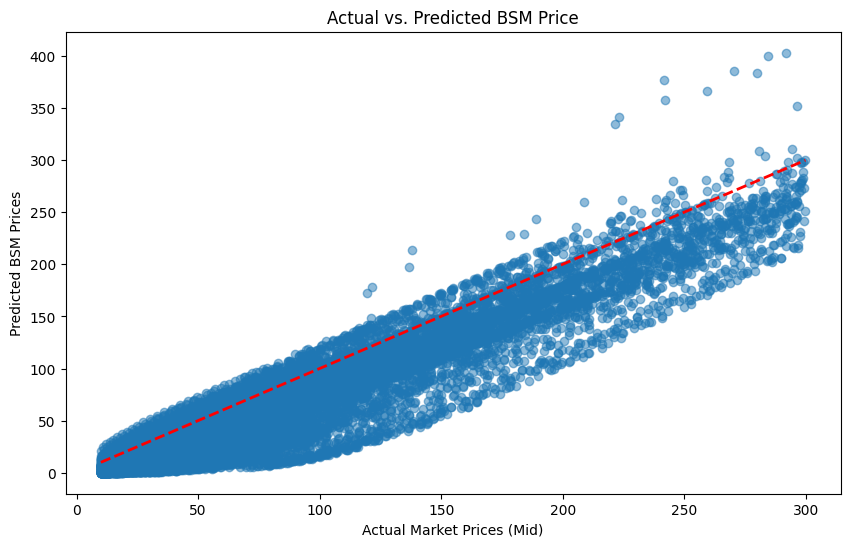

"\n# Plotting Prediction Error\nerrors = option_data['Mid'] - option_data['BSM Price']\nplt.figure(figsize=(10, 6))\nplt.plot(errors, label='Prediction Error (Mid - BSM Price)')\nplt.xlabel('Option Index')\nplt.ylabel('Prediction Error')\nplt.title('Prediction Error of BSM Price')\nplt.axhline(y=0, color='r', linestyle='--')\nplt.legend()\nplt.show()\n"

In [113]:
mae = mean_absolute_error(option_data['Mid'], option_data['BSM Price'])
mse = mean_squared_error(option_data['Mid'], option_data['BSM Price'])
r2 = r2_score(option_data['Mid'], option_data['BSM Price'])

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f}")
print(f"R-squared (R²): {r2:.2f}")

# Plotting Actual vs. Predicted (BSM) Prices
plt.figure(figsize=(10, 6))
plt.scatter(option_data['Mid'], option_data['BSM Price'], alpha=0.5)
plt.xlabel('Actual Market Prices (Mid)')
plt.ylabel('Predicted BSM Prices')
plt.title('Actual vs. Predicted BSM Price')
plt.plot([option_data['Mid'].min(), option_data['Mid'].max()], [option_data['Mid'].min(), option_data['Mid'].max()], 'k--', lw=2, color="r")
plt.show()
"""
# Plotting Prediction Error
errors = option_data['Mid'] - option_data['BSM Price']
plt.figure(figsize=(10, 6))
plt.plot(errors, label='Prediction Error (Mid - BSM Price)')
plt.xlabel('Option Index')
plt.ylabel('Prediction Error')
plt.title('Prediction Error of BSM Price')
plt.axhline(y=0, color='r', linestyle='--')
plt.legend()
plt.show()
"""

## BSM price with Implied Vol (Dupire ?)

In [114]:
def black_scholes_IV(row):
    S = row['Spot']  # Spot price
    K = row['Strike']  # Strike price
    T = row['DaysToMaturity'] / 365.25  # Convert days to years
    r = 0.04#row['Rate']/100  # Risk-free rate
    sigma = row['IV'] #/100  # Implied volatility
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if row['Type'] == 'Call':
        price = (S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2))
    else:  # Put
        price = (K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1))
    return price

option_data['Dupire Price'] = option_data.apply(black_scholes_IV, axis=1)

Mean Absolute Error (MAE): 5.89
Root Mean Squared Error (RMSE): 8.39
R-squared (R²): 0.98


C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\585807045.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([option_data['Mid'].min(), option_data['Mid'].max()], [option_data['Mid'].min(), option_data['Mid'].max()], 'k--', lw=2, color="r")


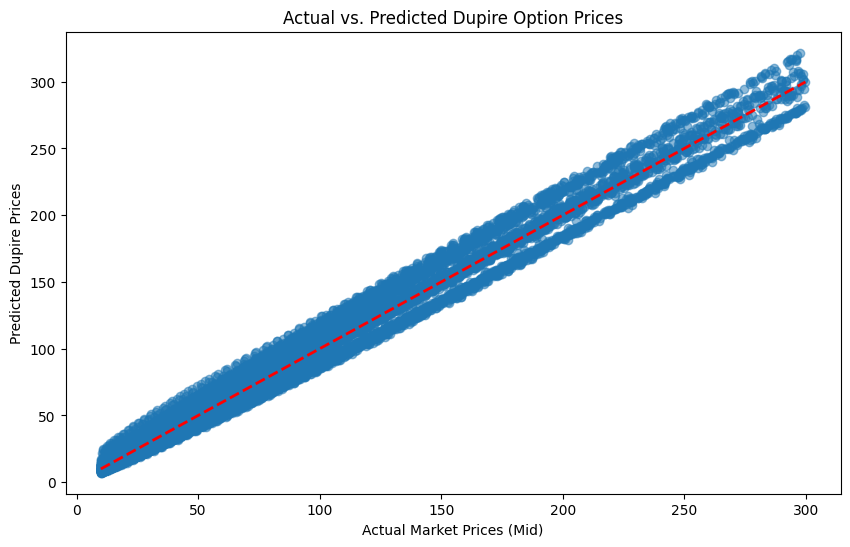

"\n# Plotting Prediction Error\nerrors = option_data['Mid'] - option_data['Dupire Price']\nplt.figure(figsize=(10, 6))\nplt.plot(errors, label='Prediction Error (Mid - Dupire Price)')\nplt.xlabel('Option Index')\nplt.ylabel('Prediction Error')\nplt.title('Prediction Error of Dupire Prices')\nplt.axhline(y=0, color='r', linestyle='--')\nplt.legend()\nplt.show()\n"

In [115]:
mae = mean_absolute_error(option_data['Mid'], option_data['Dupire Price'])
mse = mean_squared_error(option_data['Mid'], option_data['Dupire Price'])
r2 = r2_score(option_data['Mid'], option_data['Dupire Price'])

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f}")
print(f"R-squared (R²): {r2:.2f}")

# Plotting Actual vs. Predicted (BSM) Prices
plt.figure(figsize=(10, 6))
plt.scatter(option_data['Mid'], option_data['Dupire Price'], alpha=0.5)
plt.xlabel('Actual Market Prices (Mid)')
plt.ylabel('Predicted Dupire Prices')
plt.title('Actual vs. Predicted Dupire Option Prices')
plt.plot([option_data['Mid'].min(), option_data['Mid'].max()], [option_data['Mid'].min(), option_data['Mid'].max()], 'k--', lw=2, color="r")
plt.show()
"""
# Plotting Prediction Error
errors = option_data['Mid'] - option_data['Dupire Price']
plt.figure(figsize=(10, 6))
plt.plot(errors, label='Prediction Error (Mid - Dupire Price)')
plt.xlabel('Option Index')
plt.ylabel('Prediction Error')
plt.title('Prediction Error of Dupire Prices')
plt.axhline(y=0, color='r', linestyle='--')
plt.legend()
plt.show()
"""

## Heston Price

In [116]:
"""
def heston_charfunc(phi, S0, v0, kappa, theta, sigma, rho, lambd, tau, r):
    
    # constants
    a = kappa*theta
    b = kappa+lambd
    
    # common terms w.r.t phi
    rspi = rho*sigma*phi*1j
    
    # define d parameter given phi and b
    d = np.sqrt( (rho*sigma*phi*1j - b)**2 + (phi*1j+phi**2)*sigma**2 )
    
    # define g parameter given phi, b and d
    g = (b-rspi+d)/(b-rspi-d)
    
    # calculate characteristic function by components
    exp1 = np.exp(r*phi*1j*tau)
    term2 = S0**(phi*1j) * ( (1-g*np.exp(d*tau))/(1-g) )**(-2*a/sigma**2)
    exp2 = np.exp(a*tau*(b-rspi+d)/sigma**2 + v0*(b-rspi+d)*( (1-np.exp(d*tau))/(1-g*np.exp(d*tau)) )/sigma**2)

    return exp1*term2*exp2
"""

def heston_charfunc(phi, S0, v0, kappa, theta, sigma, rho, lambd, tau, r):
    # Constants and parameter adjustments
    a = kappa * theta
    b = kappa + lambd
    rspi = rho * sigma * phi * 1j
    eps = 1e-10  # Small offset to avoid division by zero

    # Define d parameter
    d = np.sqrt((rspi - b) ** 2 + (phi * 1j + phi ** 2) * sigma ** 2)

    # Define g parameter
    g = (b - rspi + d) / (b - rspi - d + eps)

    # Calculate components of the characteristic function
    exp1 = np.exp(r * phi * 1j * tau)
    g_term = (1 - g * np.exp(d * tau))
    if np.abs(g_term) < eps:
        g_term = eps
    term2 = (S0 ** (phi * 1j)) * ((g_term) / (1 - g + eps)) ** (-2 * a / sigma ** 2)
    exp2 = np.exp(a * tau * (b - rspi + d) / sigma ** 2 + v0 * (b - rspi + d) * ((1 - np.exp(d * tau)) / (g_term)) / sigma ** 2)

    return exp1 * term2 * exp2


def integrand(phi,K, S0, v0, kappa, theta, sigma, rho, lambd, tau, r):
    try:
        args = (S0, v0, kappa, theta, sigma, rho, lambd, tau, r)
        numerator = np.exp(r*tau)*heston_charfunc(phi-1j,*args) - K*heston_charfunc(phi,*args)
        denominator = 1j*phi*K**(1j*phi)
        return numerator/denominator
    except OverflowError:
        return 0
"""
def heston_price_rec(S0, K, v0, kappa, theta, sigma, rho, lambd, tau, r):
    args = (S0, v0, kappa, theta, sigma, rho, lambd, tau, r)
    
    P, umax, N = 0, 100, 10000
    dphi=umax/N #dphi is width

    for i in range(1,N):
        # rectangular integration
        phi = dphi * (2*i + 1)/2 # midpoint to calculate height
        numerator = np.exp(r*tau)*heston_charfunc(phi-1j,*args) - K * heston_charfunc(phi,*args)
        denominator = 1j*phi*K**(1j*phi)
        
        P += dphi * numerator/denominator
        
    return np.real((S0 - K*np.exp(-r*tau))/2 + P/np.pi)
"""

#More precise
def heston_price_rec(S0, K, v0, kappa, theta, sigma, rho, lambd, tau, r, option_type):
    args = (S0, v0, kappa, theta, sigma, rho, lambd, tau, r)
    
    P, umax, N = 0, 100, 10000
    #P, umax, N = 0, 200, 20000
    dphi = umax / N  # dphi is width

    for i in range(1, N):
        # Rectangular integration using the midpoint rule
        phi = dphi * (2 * i + 1) / 2  # Midpoint to calculate height
        numerator = np.exp(r * tau) * heston_charfunc(phi - 1j, *args) - K * heston_charfunc(phi, *args)
        denominator = 1j * phi * K ** (1j * phi)
        
        P += dphi * numerator / denominator
        
    # Compute the price from the real part of the integral result
    if option_type.lower() == 'call':
        return np.real((S0 - K * np.exp(-r * tau)) / 2 + P / np.pi)
    else:  # Compute the put price using the put-call parity if 'put' is specified
        call_price = np.real((S0 - K * np.exp(-r * tau)) / 2 + P / np.pi)
        put_price = call_price - S0 + K * np.exp(-r * tau)
        return put_price


def heston_price(S0, K, v0, kappa, theta, sigma, rho, lambd, tau, r, option_type):
    # Ensuring that 'K' is also passed to 'integrand'
    args = (K, S0, v0, kappa, theta, sigma, rho, lambd, tau, r)  # 'K' included at the start
    real_integral, err = quad(integrand, 0, 1000, args=args)
    C = (S0 - K*np.exp(-r*tau))/2 + real_integral/np.pi
    if option_type == 'Call' : 
        return C
    else : return C - S0 + K * np.exp(-r * tau)


# Paramètres calibrés ... Calibration à améliorer (sur autre workbook) / rendre plus efficiente : trop longue et trop peu précise 
"""
V Optimized Parameters: kappa, theta, sigma, rho, lambd, v0 = [ 1.97590419 0.28603668 0.87293317 -0.51169262 0.38240857 0.18189543]
V Optimized parameters : kappa sigma rho = [ 1.94672706 0.68071191 -0.53282122] with v0 = 0.23, theta = 0.23, lambd = 0
V Optimized parameters : kappa sigma rho = [ 0.91546582 0.26325824 -0.52765504] with v0 = 0.23, theta = 0.23, lambd = 0 with more data
V Optimized parameters : kappa sigma rho = [ 2.07673065 0.37993998 -0.70559848] with v0 = 0.23, theta = 0.23, lambd = 0 with EVEN more data
V OK 1 Optimized parameters : kappa sigma rho = [ 0.49846034 0.56942014 -0.56090413] with v0 = 0.23, theta = 0.23, lambd = 0 with EVEN more data
V Optimized parameters : kappa sigma rho = [ 1.38862568 0.64468182 -0.94955944] with v0 = 0.23, theta = 0.23, lambd = 0 with EVEN more data
V Optimized parameters : kappa sigma rho = [ 2.32144983 0.14868047 -0.84942791] with v0 = 0.23, theta = 0.23, lambd = 0 with EVEN more data
V OK 2 Optimized parameters : kappa sigma rho = [ 0.90630302 0.93611521 -0.5586409 ] with v0 = 0.23, theta = 0.23, lambd = 0 with ALL data and 1000

All parameters tried, 
Parameters kappa sigma rho = [ 0.49846034 0.56942014 -0.56090413] with v0 = 0.23, theta = 0.23, lambd = 0
provide the lower MAE 21.5, RMSE 42.67, R2 0.55 (with born sup 100)
"""

def apply_heston(row):
    S0 = row['Spot']
    K = row['Strike']
    v0 = row['hist_vol'] ** 2  # Assuming IV column is the implied volatility, square it to get the initial variance
    kappa = 0.49846034  # Example value, adjust as needed
    theta = 0.23  # Long term variance, can be set as initial variance or another estimate
    sigma = 0.56942014  # Volatility of variance, adjust based on your estimation or calibration
    rho = -0.56090413  # Correlation between asset returns and variance, adjust as necessary
    lambd = 0  # Risk premium on the variance, usually set to zero
    tau = row['DaysToMaturity'] / 365  # Converts days to years
    r = row['Rate']  # Risk-free rate
    option_type = row['Type'] 

    try:
        # Try using the more robust scipy quad integration method
        price = heston_price(S0, K, v0, kappa, theta, sigma, rho, lambd, tau, r, option_type)
        if np.isnan(price) or np.isinf(price) or price == 0:
            raise ValueError("Invalid price computed.")
    except Exception as e:
        # If an error occurs, or if price is NaN, Inf, or 0, use the rectangular midpoint integration method
        print(f"Using heston_price_rec due to error or non-finite result in heston_price: {e}")
        price = heston_price_rec(S0, K, v0, kappa, theta, sigma, rho, lambd, tau, r, option_type)

    if np.isnan(price) or np.isinf(price) or price == 0:
        print(f"heston_price_rec price still error or non-finite result")
    
    return price


# Apply the function across the DataFrame
option_data['Heston_Price'] = option_data.apply(apply_heston, axis=1)

sound_end_code()

C:\Dex\application\python\Lib\site-packages\scipy\integrate\_quadpack_py.py:611: ComplexWarning: Casting complex values to real discards the imaginary part
  return _quadpack._qagse(func,a,b,args,full_output,epsabs,epsrel,limit)
C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\372828193.py:40: RuntimeWarning: overflow encountered in exp
  g_term = (1 - g * np.exp(d * tau))
C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\372828193.py:40: RuntimeWarning: invalid value encountered in scalar multiply
  g_term = (1 - g * np.exp(d * tau))
C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\372828193.py:44: RuntimeWarning: overflow encountered in exp
  exp2 = np.exp(a * tau * (b - rspi + d) / sigma ** 2 + v0 * (b - rspi + d) * ((1 - np.exp(d * tau)) / (g_term)) / sigma ** 2)
C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\372828193.py:44: RuntimeWarning: invalid value encountered in scalar divide
  exp2 = np.exp(a * tau * (b - rspi + d) / sigma ** 2 + v0 * (b - rspi + d) * ((1 - np

Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.


C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\372828193.py:103: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  real_integral, err = quad(integrand, 0, 1000, args=args)


Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_r

C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\372828193.py:43: RuntimeWarning: invalid value encountered in scalar divide
  term2 = (S0 ** (phi * 1j)) * ((g_term) / (1 - g + eps)) ** (-2 * a / sigma ** 2)


Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.
Using heston_price_rec due to error or non-finite result in heston_price: Invalid price computed.


In [117]:
print(option_data['Heston_Price'].isna().sum())
#option_data['Heston_Price'] = option_data['Heston_Price'].fillna(0)

0


## problème avec la borne sup de mon intégrale à résoudre qui fait que le modèle est moins accurate et j'ai un prix en partie trop élevé si elle est trop basse, mais si je la monte (should be np.inf) j'ai une erreur et des 0 ... mais les prix qui sont pas à 0 sont très accurate ! plus que BSM on dirait 

### a born sup 100 pas de 0 mais prix surestimés


### a born sup 500 mieux mais pareil

### a 1 000 on a des 0 mais on se rapproche beaucoup de la ligne au dessus. à 5000, 10000 on se rapproche de la ligne mais on a encore plus de 0.

### Essai avec la fonction heston price rec (moins précise mais moins complexe et susceptible de retourner une erreur) si heston_price sup 10000 retourne 0 -> mieux mais heston_price_rec a le même problème que la sup borne, donc le prix est surevalué aussi, prochaine je lance avec le np.inf pour heston price et avec des paramètres plus précis pour heston_price_rec mais ca va tourner beaucoup plus longtemps ! Mais au mloins plus de NA donc plus de 0 !!

### Essai avec la fonction heston price rec (moins précise mais moins complexe et susceptible de retourner une erreur) si heston_price sup np.inf retourne 0 -> trop de temps à tourner (plusieurs heures), et beaucoup d'erreurs du à la borne sup trop haute, mieux de la placer manuellement malheureusement. (-> limitation du modèle, en python et sur beaucoup de données du moins, should work sur un petit data set)

#### heston_price vs. heston_price_rec : heston_price uses adaptive numerical integration for potentially higher accuracy, while heston_price_rec uses a simpler, manual rectangular midpoint integration method that may be less accurate but gives direct control over the integration process.

Mean Absolute Error (MAE): 21.17
Root Mean Squared Error (RMSE): 41.07
R-squared (R²): 0.58


C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\1907649438.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([option_data['Mid'].min(), option_data['Mid'].max()], [option_data['Mid'].min(), option_data['Mid'].max()], 'k--', lw=2, color="r")


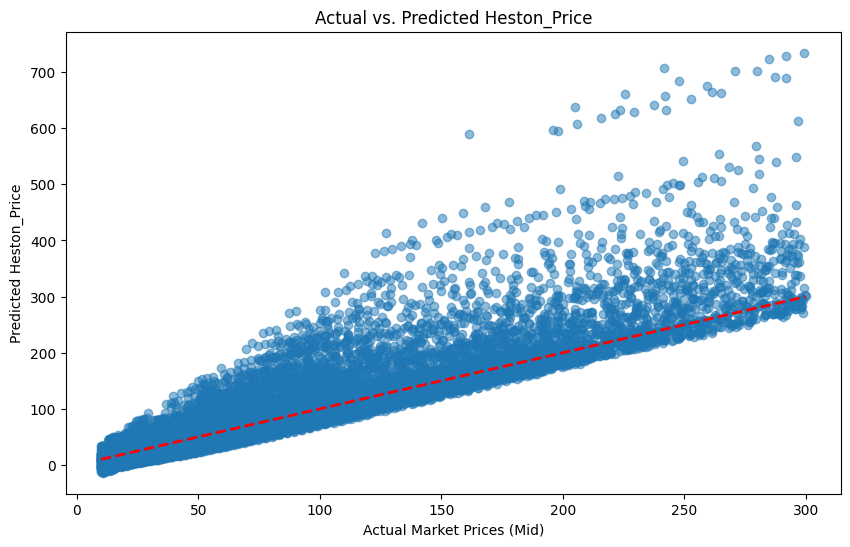

"\n# Plotting Prediction Error\nerrors = option_data['Mid'] - option_data['Heston_Price']\nplt.figure(figsize=(10, 6))\nplt.plot(errors, label='Prediction Error (Mid - Heston_Price)')\nplt.xlabel('Option Index')\nplt.ylabel('Prediction Error')\nplt.title('Prediction Error of Heston_Price')\nplt.axhline(y=0, color='r', linestyle='--')\nplt.legend()\nplt.show()\n"

In [118]:
mae = mean_absolute_error(option_data['Mid'], option_data['Heston_Price'])
mse = mean_squared_error(option_data['Mid'], option_data['Heston_Price'])
r2 = r2_score(option_data['Mid'], option_data['Heston_Price'])

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f}")
print(f"R-squared (R²): {r2:.2f}")

# Plotting Actual vs. Predicted (BSM) Prices
plt.figure(figsize=(10, 6))
plt.scatter(option_data['Mid'], option_data['Heston_Price'], alpha=0.5)
plt.xlabel('Actual Market Prices (Mid)')
plt.ylabel('Predicted Heston_Price')
plt.title('Actual vs. Predicted Heston_Price')
plt.plot([option_data['Mid'].min(), option_data['Mid'].max()], [option_data['Mid'].min(), option_data['Mid'].max()], 'k--', lw=2, color="r")
plt.show()
"""
# Plotting Prediction Error
errors = option_data['Mid'] - option_data['Heston_Price']
plt.figure(figsize=(10, 6))
plt.plot(errors, label='Prediction Error (Mid - Heston_Price)')
plt.xlabel('Option Index')
plt.ylabel('Prediction Error')
plt.title('Prediction Error of Heston_Price')
plt.axhline(y=0, color='r', linestyle='--')
plt.legend()
plt.show()
"""

# ALGO - Deep NN

## Preparation data for algo 

In [125]:
"""
data qu'on garde
"""

option_data_NN1 = option_data[option_data["Type"]=='Call'] #pour l'instant ...

option_data_NN1 = option_data_NN1[['Volume', 'hist_vol', 'DaysToMaturity', 'Mid', 'Moneyness S/K', 'Spot', 'Strike', 'Rate']] 


### Encoding categorical variables as dummies

In [126]:
categorical_columns = option_data.select_dtypes(include=['object', 'category']).columns

option_data_encoded_NN1 = pd.get_dummies(option_data, columns=categorical_columns)


In [127]:

X_col = option_data_encoded_NN1[[ 'Moneyness S/K','hist_vol', 'DaysToMaturity','Volume', 'Rate']] #"Strike", "Spot",
X = X_col.values
y = option_data_encoded_NN1[['Mid']].values

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

scaler = RobustScaler() #MinMaxScaler(), StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

In [128]:
X_train, y_train

(array([[ 1.8537126 ,  4.11635   ,  6.5882354 , -0.23684211, -2.1674914 ],
        [-0.22625288, -0.9358834 , -0.11764706,  0.        ,  0.14377804],
        [-0.735393  , -0.4775289 ,  0.01960784,  0.10526316,  0.4245689 ],
        ...,
        [-0.55722976, -0.17712338,  0.        ,  0.18421052,  0.39184803],
        [ 1.1070834 ,  0.16600429,  0.64705884, -0.21052632,  0.6259663 ],
        [ 2.867662  , -0.20070271,  0.7058824 ,  0.05263158,  0.49197695]],
       dtype=float32),
 array([[154.85],
        [ 72.45],
        [ 36.25],
        ...,
        [ 33.75],
        [ 55.6 ],
        [ 20.6 ]]))

## Preparation of the Model

In [132]:
# Definition of the model
"""
#Base Model
model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(1, activation='linear')
])
"""
# More layers
model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(1, activation='linear')
])

"""
#With more dropout (increase regularization)
model = Sequential([
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='linear')
])
"""
"""
#fewer layers or neurons
model = Sequential([
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])
"""

"""
#sans le dropout
model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='linear')
])
"""

"""
#freestyle pour tester : softplus, softmax, 
model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dense(128, activation='relu'), #256
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='linear')
])
"""


#Optimizer
optimizer = Adam(learning_rate=0.004) #0.004 est le mieux

#loss 
from keras.losses import Huber
huber_loss = Huber()

model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae']) #huber_loss


#Training of the model 
model.fit(X_train, y_train, epochs=1000, batch_size=1024, validation_split=0.2)

Epoch 1/1000


C:\Dex\application\python\Lib\site-packages\keras\src\layers\core\dense.py:85: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - loss: 10209.6211 - mae: 78.9443 - val_loss: 9034.4502 - val_mae: 70.6597
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 7747.0239 - mae: 63.7443 - val_loss: 5418.4937 - val_mae: 56.4739
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 4514.5439 - mae: 50.3920 - val_loss: 3878.3586 - val_mae: 45.4981
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 3556.1553 - mae: 44.1617 - val_loss: 3341.6787 - val_mae: 43.1249
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 3197.3799 - mae: 41.9670 - val_loss: 3111.0564 - val_mae: 42.6531
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 3085.8936 - mae: 41.7100 - val_loss: 2847.6084 - val_mae: 40.1758
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 2765.2529 - mae: 38.9980 - val_loss: 2587.1758 - val_mae: 35.9156
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 2563.9915 - mae: 36.0850 - val_loss: 2377.6665 - val_mae: 33.2

## Performance :

102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Mean Absolute Error (MAE): 28.45
Root Mean Squared Error (RMSE): 45.33
R-squared (R^2): 0.52


C:\Users\S084339\AppData\Local\Temp\ipykernel_23896\963310436.py:20: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2, color="r")


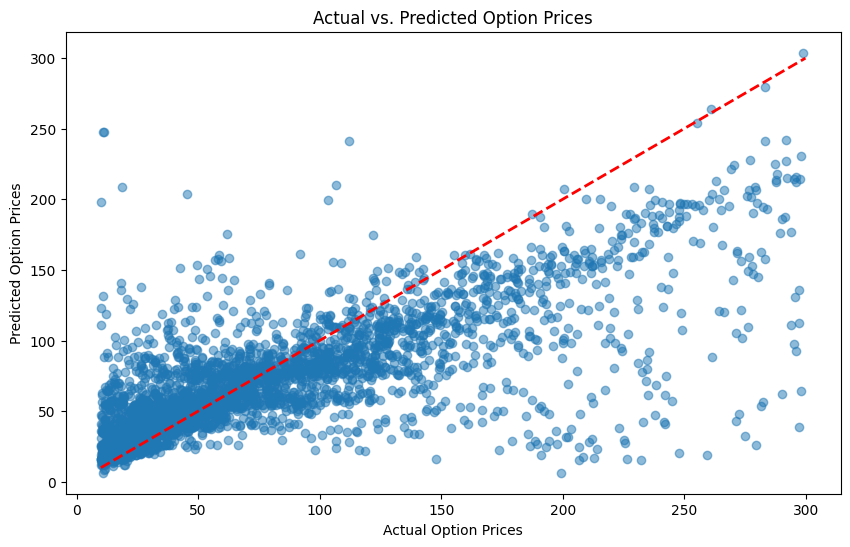

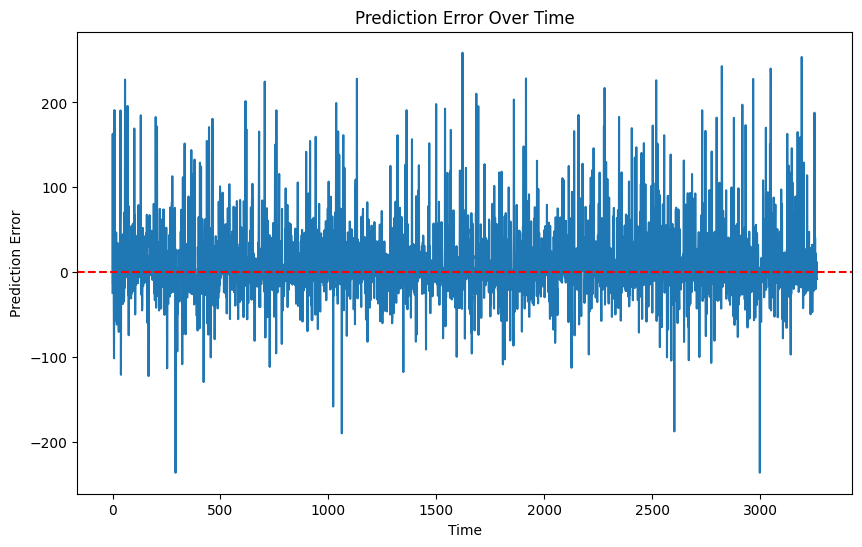

In [133]:

# Make predictions
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred) 
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f}")
print(f"R-squared (R^2): {r2:.2f}")

# Plotting Actual vs. Predicted Values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel('Actual Option Prices')
plt.ylabel('Predicted Option Prices')
plt.title('Actual vs. Predicted Option Prices')
#plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, color="r")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2, color="r")
plt.show()

# Plotting Prediction Error
errors = y_test.reshape(-1) - y_pred.reshape(-1)
plt.figure(figsize=(10, 6))
plt.plot(errors)
plt.xlabel('Time')
plt.ylabel('Prediction Error')
plt.title('Prediction Error Over Time')
plt.axhline(y=0, color='r', linestyle='--')
plt.show()

## Features importance

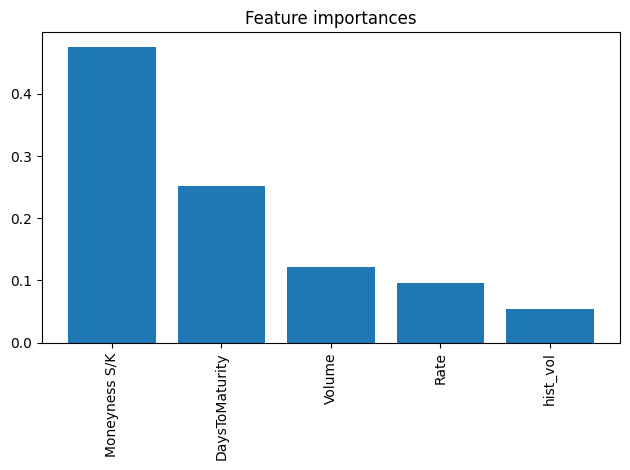

In [134]:
# Fit a random forest to check feature importance
forest = RandomForestRegressor()
forest.fit(X_train, y_train.ravel())

# Plotting feature importances
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]

# Assuming X_col is your DataFrame with the column names
column_names = X_col.columns[indices]

plt.figure()
plt.title('Feature importances')
plt.bar(range(X_train.shape[1]), importances[indices])
plt.xticks(range(X_train.shape[1]), column_names, rotation=90)  # Use actual column names
plt.tight_layout()
plt.show()


### Ici faire une table qui récap les RMSE et MAE de chaque modèle 

In [ ]:
"""

data = {
    "Metric": ["RMSE", "MAE", "R2"],
    "Heston Model": [rmse_heston, None, None],  
    "Dupire Model": [None, mae_dupire, None],  
    "Black-Scholes Model": [None, None, r2_black_scholes],
    "NN Model": [None, None, None]
    
}

performance_df = pd.DataFrame(data)

performance_df
"""